# Find Glaciers in Study Region #

## Define Region and Data

In [91]:
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from scipy.stats import chi2_contingency
from scipy.spatial.distance import cdist

#Path to RGI shp file (str):
rgi_fp = '/Users/SILASTWICKLER/ws/HMA/data/RGI2000-v7.0-G-14_south_asia_west/RGI2000-v7.0-G-14_south_asia_west.shp'
full_rgi = gpd.read_file(rgi_fp)
#RGI o2 region (str):
region = ['14-02']
#Surge types (list) (0: No, 1: Possible, 2: Probable, 3: Observed, 9: N/A 
surge = [3]
#minimum area
min_area = 100
max_area = 500

rgi = full_rgi[
    (full_rgi["o2region"].isin(region)) &
    (full_rgi["surge_type"].isin(surge)) &
    (full_rgi["area_km2"] > min_area) &
    (full_rgi["area_km2"] < max_area)
].copy()

## Graph Distribution for Different Variables

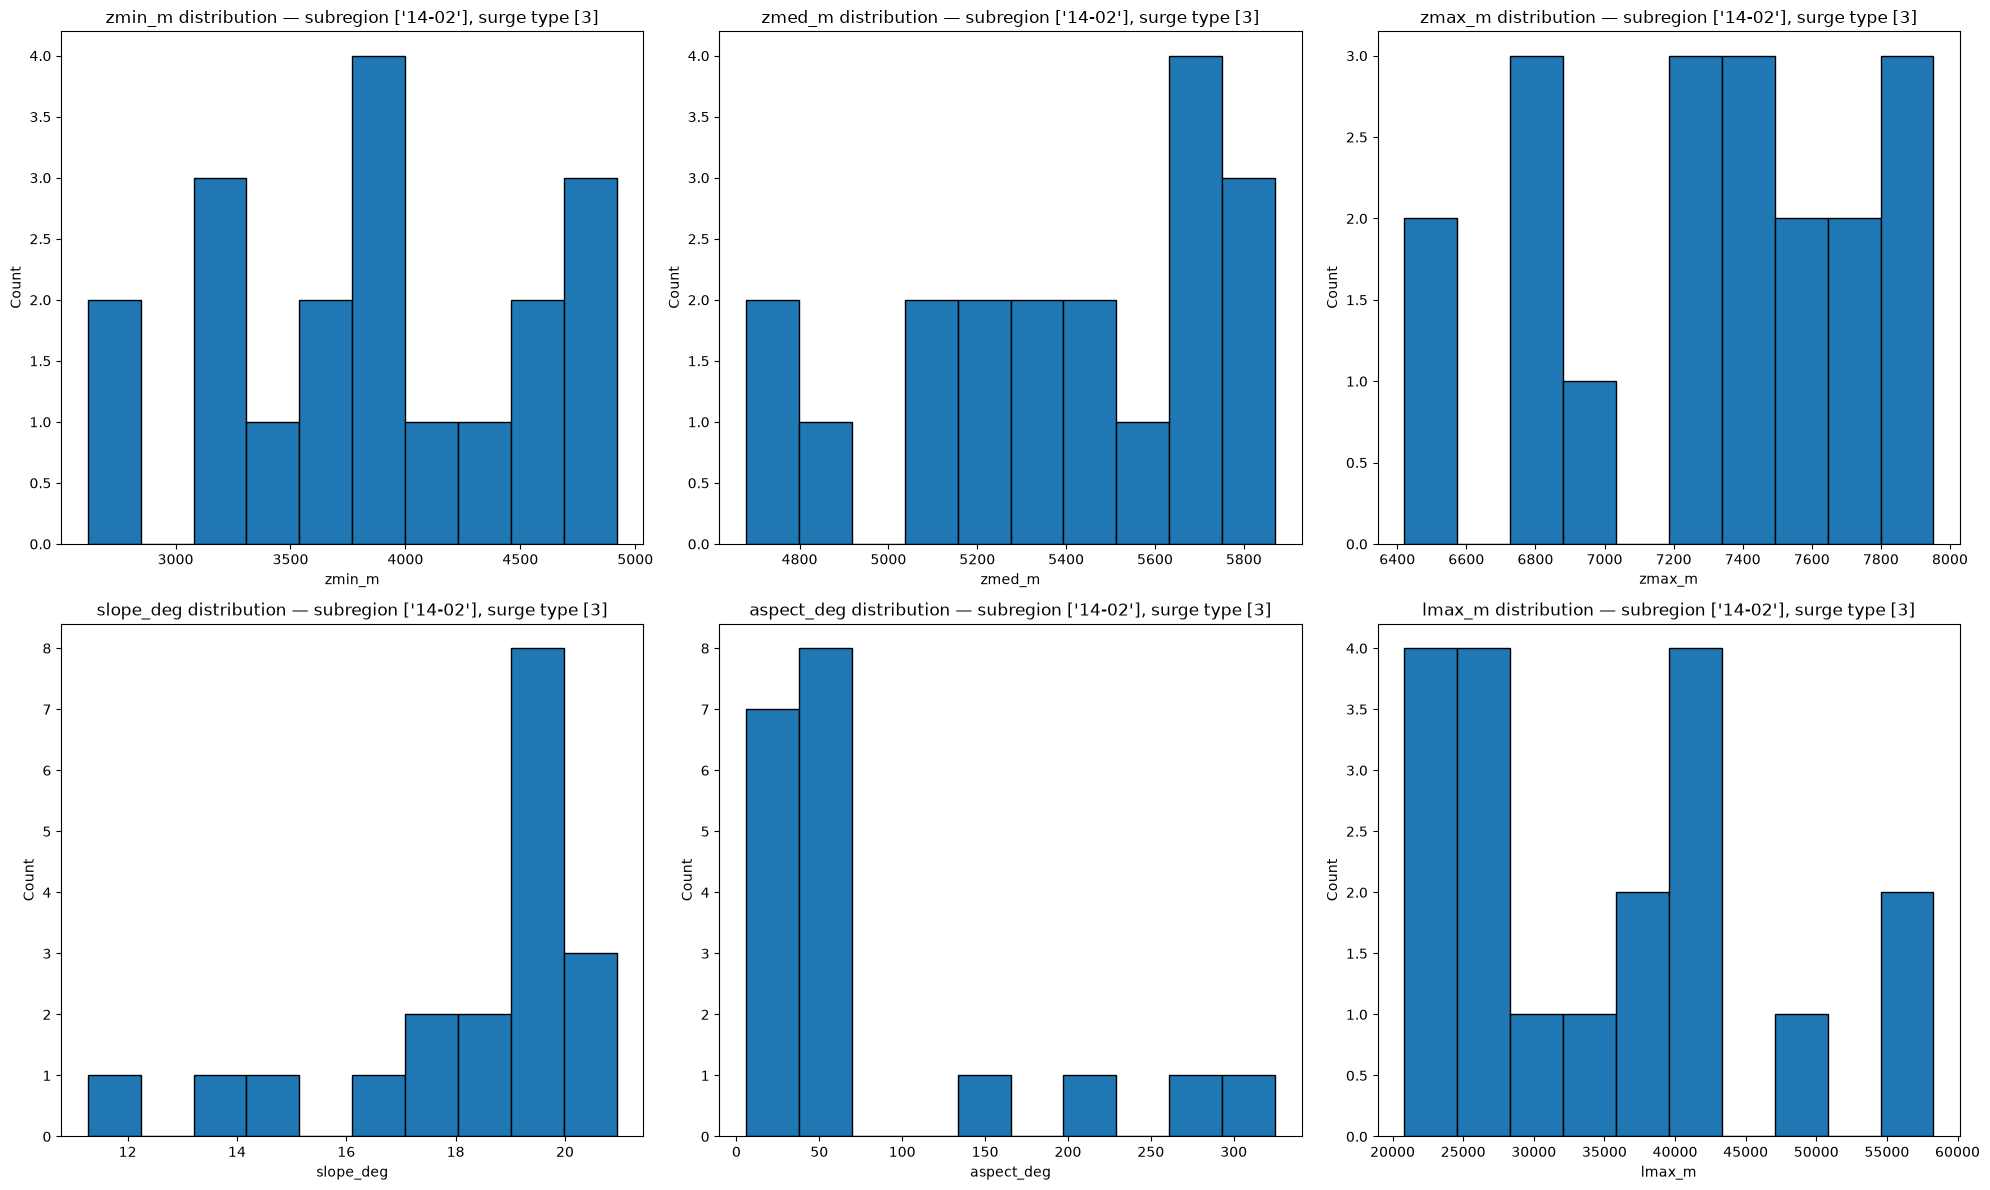

In [28]:
#Possible features: area_km2, zmin_m, zmed_m, zmean_m, zmax_m, slope_deg, aspect_deg, lmax_m
features = ['zmin_m', 'zmed_m', 'zmax_m', 'slope_deg', 'aspect_deg', 'lmax_m']

ncols = 3
nrows = int(np.ceil(len(features) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(20, 6 * nrows))
axes = np.atleast_1d(axes).flatten()  # flatten so you can index linearly regardless of shape

for i, feat in enumerate(features):
    ax = axes[i]
    rgi[feat].plot(kind="hist", bins=10, ax=ax, edgecolor="black")
    ax.set_xlabel(feat)
    ax.set_ylabel("Count")
    ax.set_title(f"{feat} distribution — subregion {region}, surge type {surge}")
    plt.tight_layout()
    #plt.savefig(figures_out_path / "rgi7_subregion_surge_hist.png", dpi=300)
plt.show()


## Manual Sorting of Dataset by Parameters

In [87]:
#Aspect
aspects = [270, 90]

south_rgi = rgi[
    (rgi["aspect_deg"] > aspects[1]) &
    (rgi["aspect_deg"] < aspects[0])
].copy()

north_rgi = rgi[
    (rgi["aspect_deg"] > aspects[0]) |
    (rgi["aspect_deg"] < aspects[1])
].copy()

elev = [5000, 5200, 5400, 5600]
elev_hi_rgi = north_rgi[
    (north_rgi["zmed_m"] > elev[3])
].copy()
elev_lo_rgi = north_rgi[
    (north_rgi["zmed_m"] < elev[0]) &
    (north_rgi["zmin_m"] < 3000)
].copy()
elev_mid_rgi = north_rgi[
    (north_rgi["zmed_m"] < elev[2]) &
    (north_rgi["zmed_m"] > elev[1])
].copy()
slopes = [13, 20]
slopes_rgi = elev_hi_rgi[
    (elev_hi_rgi["slope_deg"] < slopes[0]) |
    (elev_hi_rgi["slope_deg"] > slopes[1])
].copy()
slope_rgi = slopes_rgi[
    (slopes_rgi["slope_deg"] < slopes[0]) |
    (slopes_rgi["zmax_m"] > 7600)
].copy()


'''
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 6 * nrows))
axes = np.atleast_1d(axes).flatten()  # flatten so you can index linearly regardless of shape

for i, feat in enumerate(features):
    ax = axes[i]
    slope_rgi[feat].plot(kind="hist", bins=10, ax=ax, edgecolor="black")
    ax.set_xlabel(feat)
    ax.set_ylabel("Count")
    ax.set_title(f"{feat} distribution — subregion {region}, surge type {surge}")
    plt.tight_layout()
    #plt.savefig(figures_out_path / "rgi7_subregion_surge_hist.png", dpi=300)
plt.show()
'''

'\nfig, axes = plt.subplots(nrows, ncols, figsize=(20, 6 * nrows))\naxes = np.atleast_1d(axes).flatten()  # flatten so you can index linearly regardless of shape\n\nfor i, feat in enumerate(features):\n    ax = axes[i]\n    slope_rgi[feat].plot(kind="hist", bins=10, ax=ax, edgecolor="black")\n    ax.set_xlabel(feat)\n    ax.set_ylabel("Count")\n    ax.set_title(f"{feat} distribution — subregion {region}, surge type {surge}")\n    plt.tight_layout()\n    #plt.savefig(figures_out_path / "rgi7_subregion_surge_hist.png", dpi=300)\nplt.show()\n'

## Save Manually Sorted Data

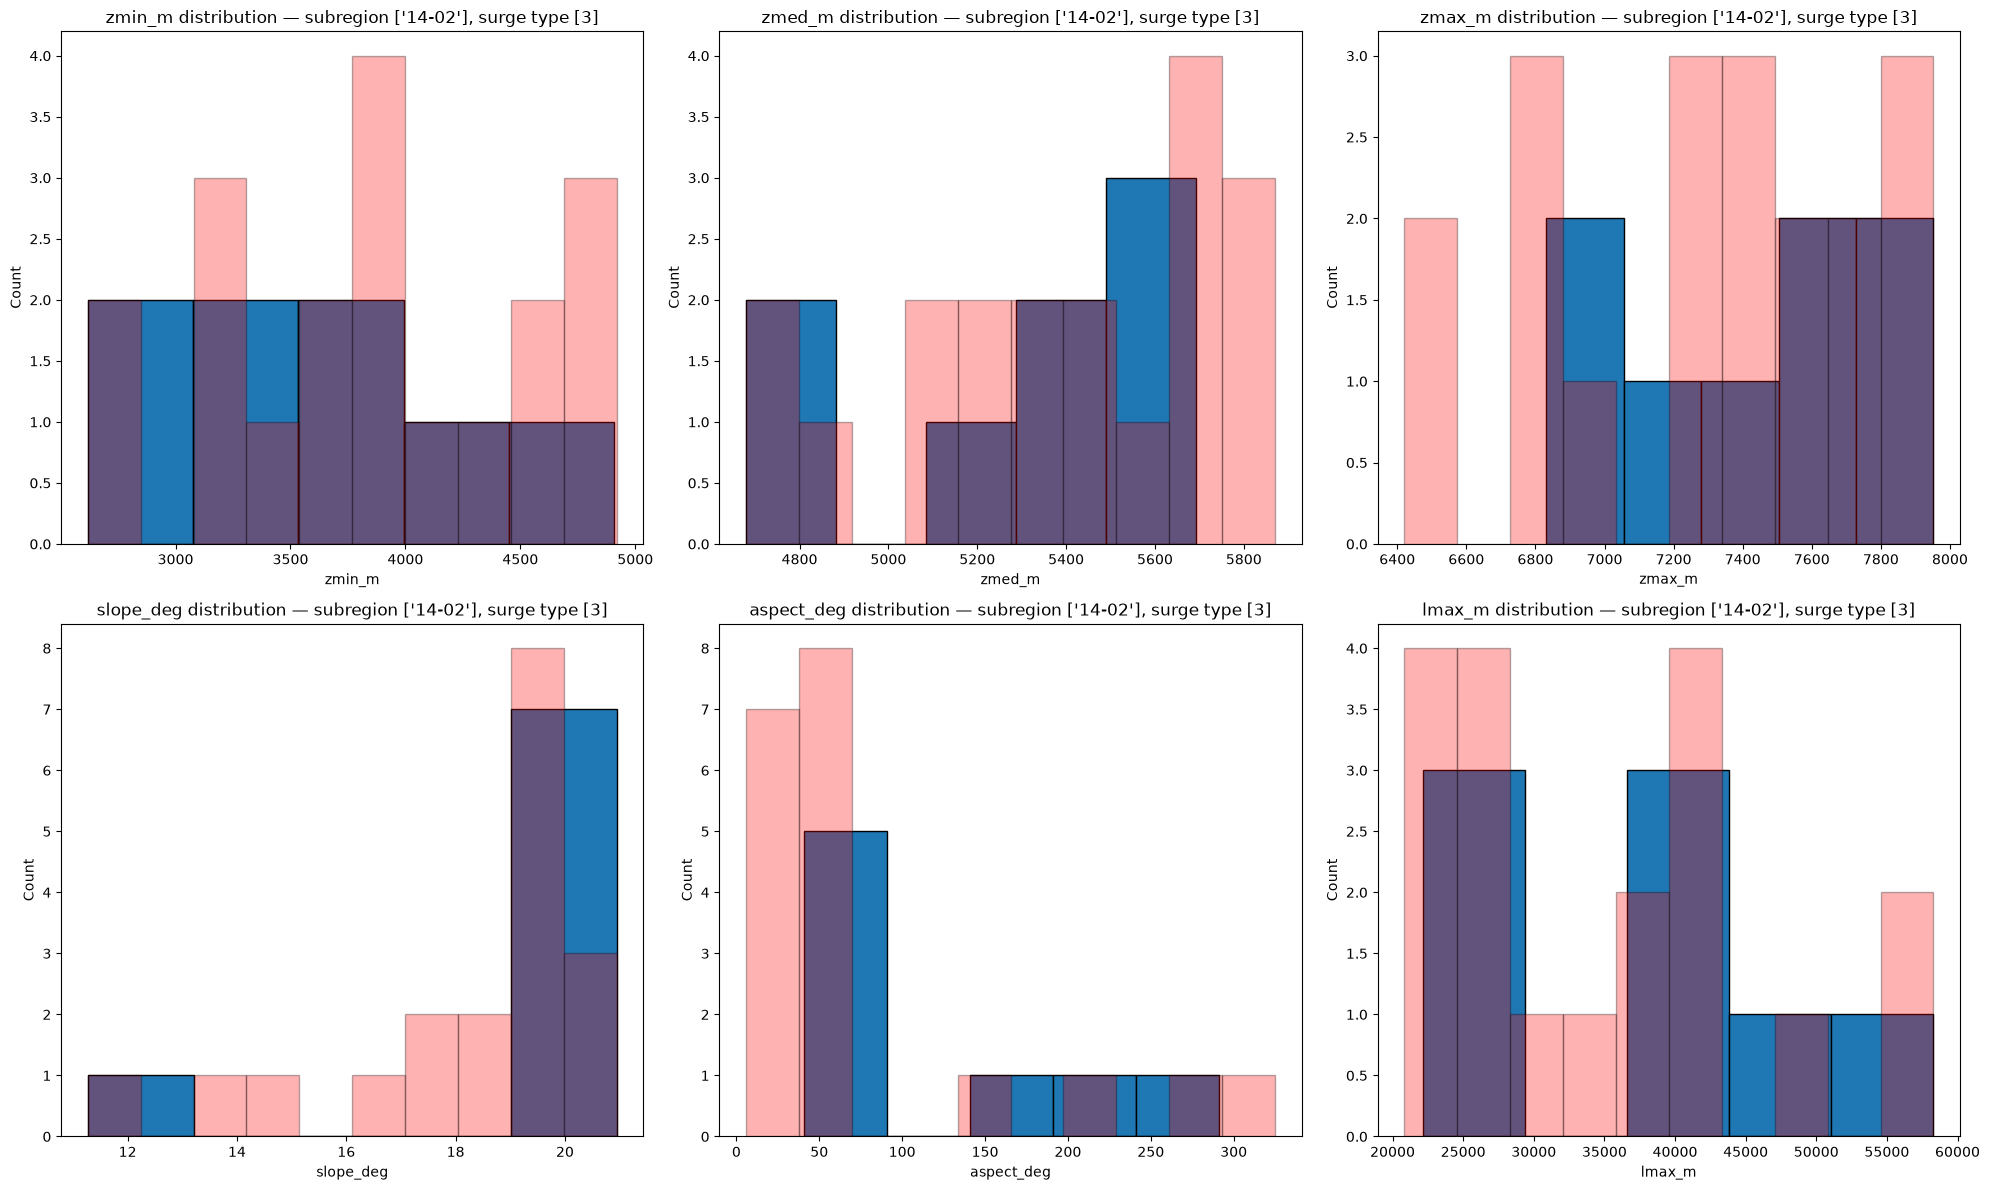

Chi^2: 5.303571428571429, p: 0.3799657755528258, dof: 5, exp: [[4.92592593 5.62962963 2.81481481 2.81481481 2.11111111 0.7037037 ]
 [2.07407407 2.37037037 1.18518519 1.18518519 0.88888889 0.2962963 ]]


/Users/SILASTWICKLER/ws/micromamba/envs/gscm/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


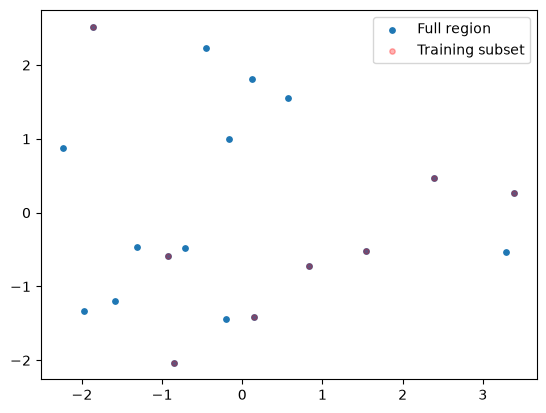

In [99]:
#Outpath
rgi_out_path = Path('/Users/SILASTWICKLER/ws/HMA/data/training_glaciers/karakoram')
rgi_out_path.mkdir(parents=True, exist_ok=True)

#Combine all data:
rgi_subsets = gpd.GeoDataFrame()
rgi_subsets = pd.concat([rgi_subsets, south_rgi], ignore_index=True)
rgi_subsets = pd.concat([rgi_subsets, slope_rgi], ignore_index=True)
rgi_subsets = pd.concat([rgi_subsets, elev_lo_rgi], ignore_index=True)
rgi_subsets = pd.concat([rgi_subsets, elev_mid_rgi], ignore_index=True)

manual_rgi_subsets = gpd.GeoDataFrame(rgi_subsets, geometry="geometry", crs=rgi.crs)

#Visualize distribution:
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 6 * nrows))
axes = np.atleast_1d(axes).flatten()  # flatten so you can index linearly regardless of shape

for i, feat in enumerate(features):
    ax = axes[i]
    manual_rgi_subsets[feat].plot(kind="hist", bins=5, ax=ax, edgecolor="black")
    rgi[feat].plot(kind="hist", color = 'red', alpha = 0.3, bins=10, ax=ax, edgecolor="black")
    ax.set_xlabel(feat)
    ax.set_ylabel("Count")
    ax.set_title(f"{feat} distribution — subregion {region}, surge type {surge}")
    plt.tight_layout()
    #plt.savefig(figures_out_path / "rgi7_subregion_surge_hist.png", dpi=300)
plt.show()

rgi_subset = manual_rgi_subsets

# Clustering
X_full = StandardScaler().fit_transform(rgi[features])
scaler = StandardScaler().fit(rgi[features])
X_full = scaler.transform(rgi[features])

km = KMeans(n_clusters=6, random_state=1).fit(X_full)
rgi['cluster'] = km.labels_

# assign subset to the same clusters (don't refit)
X_sub = scaler.transform(rgi_subset[features])
rgi_subset['cluster'] = km.predict(X_sub)

# compare proportions
full_props = rgi['cluster'].value_counts(normalize=True).sort_index()
sub_props  = rgi_subset['cluster'].value_counts(normalize=True).sort_index()

contingency = pd.concat([rgi['cluster'].value_counts(),
                          rgi_subset['cluster'].value_counts()], axis=1).fillna(0)
chi2, p, dof, exp = chi2_contingency(contingency.T)

print(f'Chi^2: {chi2}, p: {p}, dof: {dof}, exp: {exp}')

pca = PCA(n_components=2).fit(X_full)
proj_full = pca.transform(X_full)
proj_sub  = pca.transform(X_sub)

fig, ax = plt.subplots()
ax.scatter(*proj_full.T, s=15, alpha=1, label='Full region')
ax.scatter(*proj_sub.T, s=15, color='red', alpha = 0.3, label='Training subset')
ax.legend()
plt.show()

#Save Data
#manual_subsets_file = rgi_out_path / 'manual_training_glaciers.gpkg'
#manual_rgi_subsets.to_file(manual_subsets_file, driver="GPKG")


## Autotmatic Sorting Using k-medoid Clustering

Chi^2: 1.114210526315789, p: 0.9528381365635192, dof: 5, exp: [[5.89655172 3.93103448 3.27586207 1.96551724 2.62068966 1.31034483]
 [3.10344828 2.06896552 1.72413793 1.03448276 1.37931034 0.68965517]]


/Users/SILASTWICKLER/ws/micromamba/envs/gscm/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(
/Users/SILASTWICKLER/ws/micromamba/envs/gscm/lib/python3.11/site-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


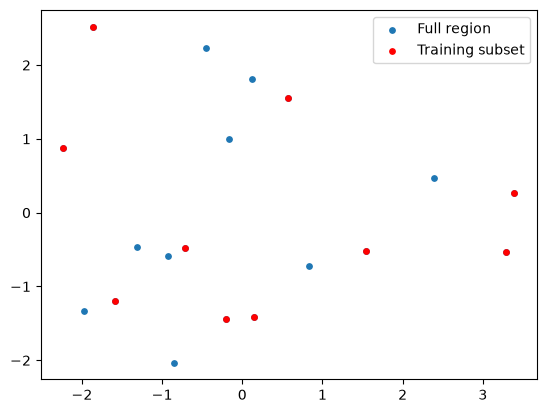

In [95]:
#This method uses the k-medoid style and captures an even spread across the full feature space. (Maximizes generalization but not porportional to population)

features = ['zmin_m', 'zmed_m', 'zmax_m', 'slope_deg', 'aspect_deg', 'lmax_m']

N = 10

scaler = StandardScaler().fit(rgi[features])
X = scaler.transform(rgi[features])

km_N = KMeans(n_clusters=N, random_state=1).fit(X)
rgi['cluster_N'] = km_N.labels_

selected_idx = []
for cl in range(N):
    members = np.where(rgi['cluster_N'] == cl)[0]
    centroid = km_N.cluster_centers_[cl]
    dists = cdist(X[members], centroid.reshape(1, -1)).ravel()
    selected_idx.append(members[np.argmin(dists)])  # medoid: closest glacier to centroid

auto_rgi_subset = rgi.iloc[selected_idx].reset_index(drop=True)

rgi_subset = auto_rgi_subset

# Clustering
X_full = StandardScaler().fit_transform(rgi[features])
scaler = StandardScaler().fit(rgi[features])
X_full = scaler.transform(rgi[features])

km = KMeans(n_clusters=6, random_state=1).fit(X_full)
rgi['cluster'] = km.labels_

# assign subset to the same clusters (don't refit)
X_sub = scaler.transform(rgi_subset[features])
rgi_subset['cluster'] = km.predict(X_sub)

# compare proportions
full_props = rgi['cluster'].value_counts(normalize=True).sort_index()
sub_props  = rgi_subset['cluster'].value_counts(normalize=True).sort_index()

contingency = pd.concat([rgi['cluster'].value_counts(),
                          rgi_subset['cluster'].value_counts()], axis=1).fillna(0)
chi2, p, dof, exp = chi2_contingency(contingency.T)

print(f'Chi^2: {chi2}, p: {p}, dof: {dof}, exp: {exp}')

pca = PCA(n_components=2).fit(X_full)
proj_full = pca.transform(X_full)
proj_sub_auto  = pca.transform(X_sub)

fig, ax = plt.subplots()
ax.scatter(*proj_full.T, s=15, alpha=1, label='Full region')
ax.scatter(*proj_sub_auto.T, s=15, color='red', alpha = 1, label='Training subset')
ax.legend()
plt.show()

#Save Data
#auto_subsets_file = rgi_out_path / 'k-medoid_training_glaciers.gpkg'
#auto_rgi_subset.to_file(auto_subsets_file, driver="GPKG")

## Compare Manual vs Automatic

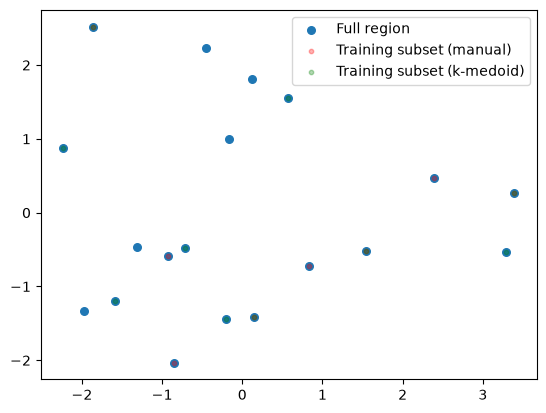

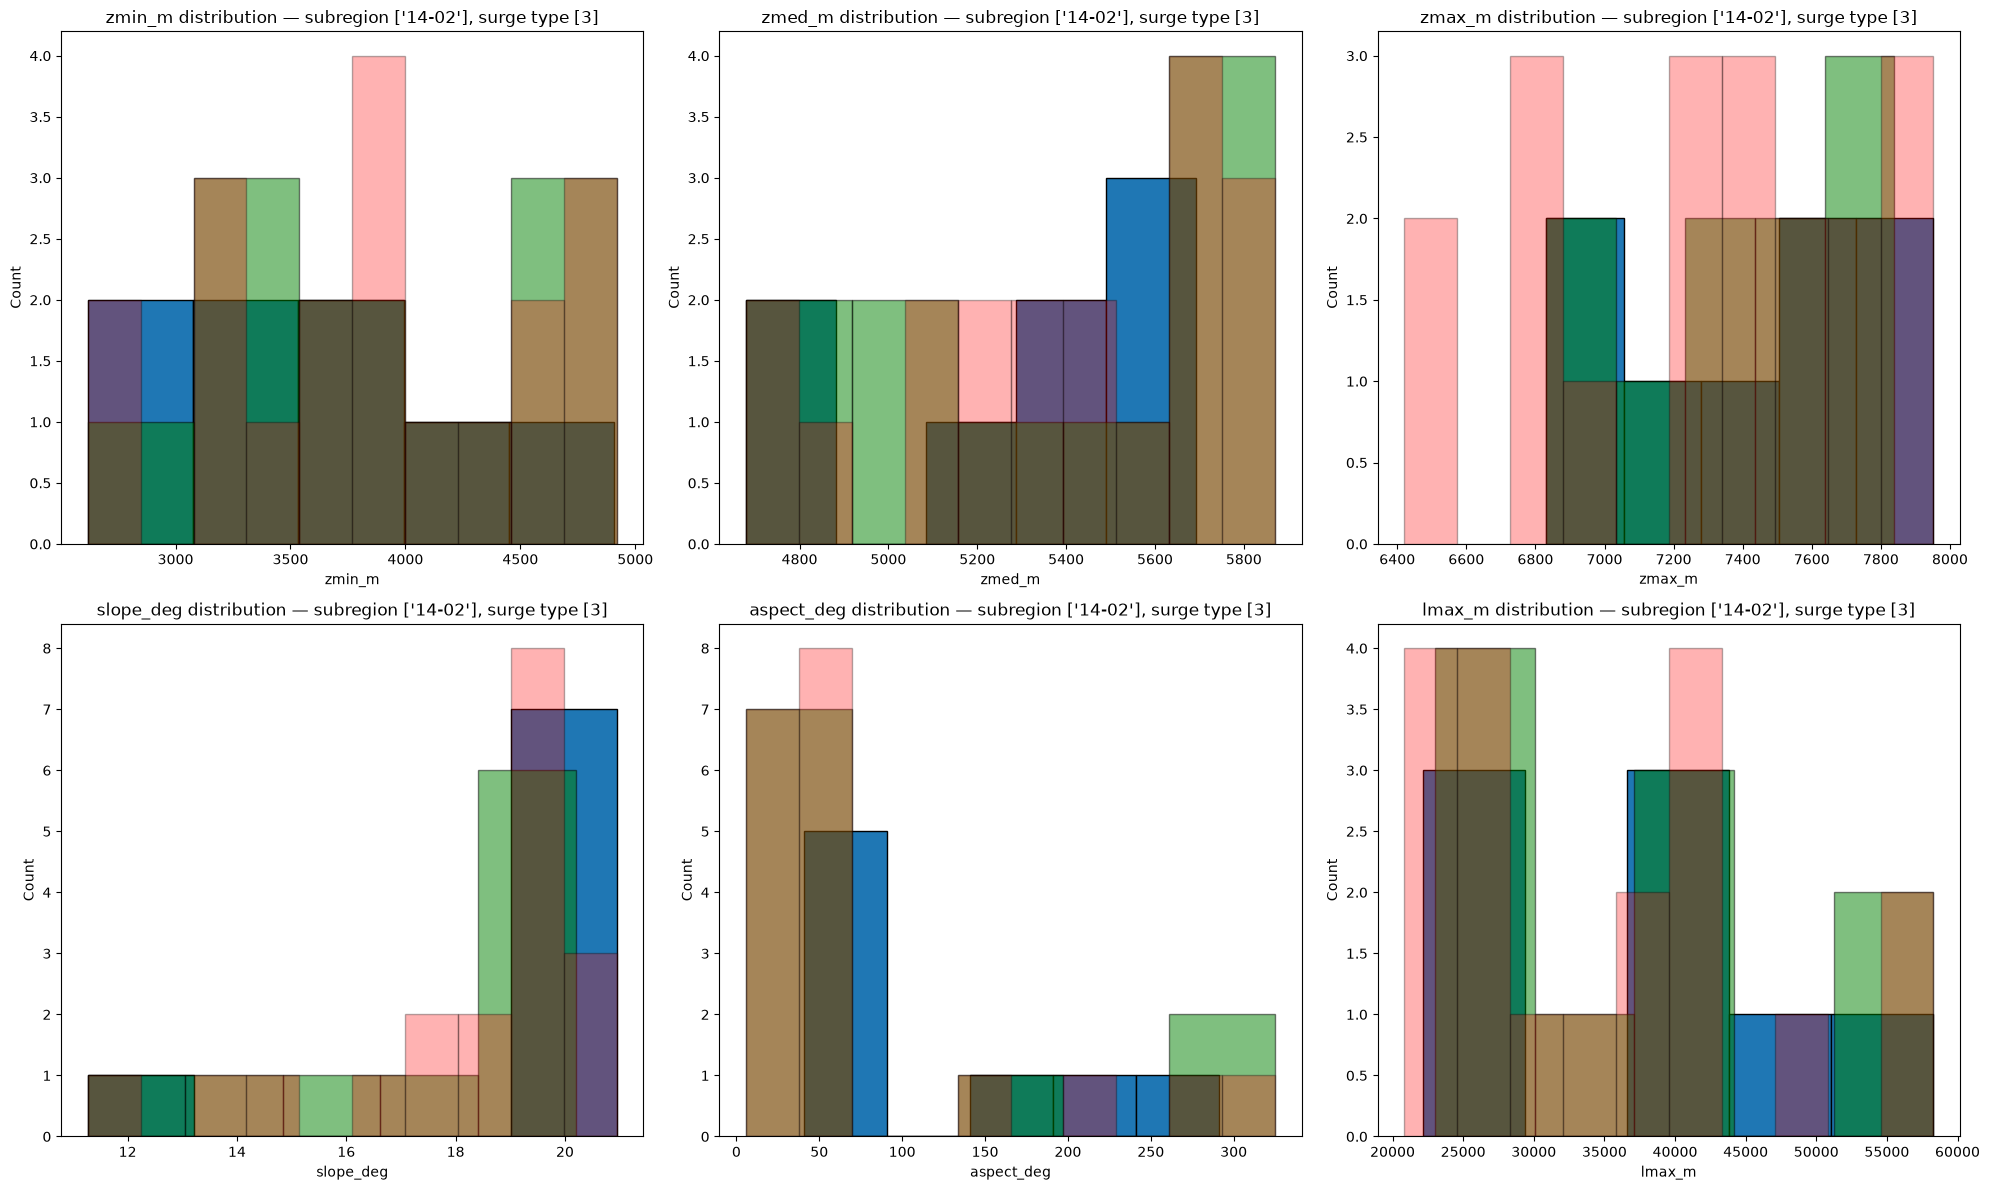

In [104]:
fig, ax = plt.subplots()
ax.scatter(*proj_full.T, s=30, alpha=1, label='Full region')
ax.scatter(*proj_sub.T, s=10, color='red', alpha = 0.3, label='Training subset (manual)')
ax.scatter(*proj_sub_auto.T, s=10, color='green', alpha = 0.3, label='Training subset (k-medoid)')
ax.legend()
plt.show()

fig, axes = plt.subplots(nrows, ncols, figsize=(20, 6 * nrows))
axes = np.atleast_1d(axes).flatten()  # flatten so you can index linearly regardless of shape

for i, feat in enumerate(features):
    ax = axes[i]
    manual_rgi_subsets[feat].plot(kind="hist", bins=5, ax=ax, edgecolor="black")
    auto_rgi_subset[feat].plot(kind="hist", color = 'green', alpha = 0.5, bins=5, ax=ax, edgecolor="black")
    rgi[feat].plot(kind="hist", color = 'red', alpha = 0.3, bins=10, ax=ax, edgecolor="black")
    ax.set_xlabel(feat)
    ax.set_ylabel("Count")
    ax.set_title(f"{feat} distribution — subregion {region}, surge type {surge}")
    plt.tight_layout()
    #plt.savefig(figures_out_path / "rgi7_subregion_surge_hist.png", dpi=300)
plt.show()